# Where do the waves vary most, and what OLR structures accompany them?

Compare **NOAA CDR OLR**, **CNRM-CM6-1 historical r1i1p1f2**, and
**HadGEM3-GC31-LL historical r1i1p1f3**, using the daily **1990–2010** records.
Each figure has one panel per wave and dataset: columns are datasets, rows are
Kelvin, n=1 ER, MRG, n=0 EIG, and n=1 WIG.

First map wave-filtered OLR variance and mark its maximum. Then regress the
unfiltered OLR anomaly field onto the filtered index at that base point.
**Every dataset and wave has its own independently selected base point.**
The compact products were calculated on Levante; this notebook only loads and
plots those products, so it also runs locally without the raw archives.

In [1]:
import hashlib
import json

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.ticker import MaxNLocator
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from cartopy.util import add_cyclic_point
from IPython.display import display

from src.paths import DATA_DIR
from src import plotting as project_plotting

PRODUCT_DIR = DATA_DIR / "olr_wave_regression" / "1990-2010"
RECORDS = (
    ("NOAA OLR", "NOAA_OLR", "observations", "not_applicable"),
    ("CNRM-CM6-1", "CNRM-CM6-1", "historical", "r1i1p1f2"),
    ("HadGEM3-GC31-LL", "HadGEM3-GC31-LL", "historical", "r1i1p1f3"),
)
WAVES = ("Kelvin", "n1ERW", "MRG", "n0EIG", "n1WIG")
WAVE_LABELS = ("Kelvin", "n=1 ER", "MRG", "n=0 EIG", "n=1 WIG")
LATITUDE_BOUND = 20
REGRESSION_AMPLITUDE_SIGMA = 1.0  # positive convection: negative filtered OLR


## Calculation and interpretation

The five **rectangular filters and symmetry projections** are the same as in
the event analysis, with **no equivalent-depth restriction**. Three seasonal
harmonics and the mean/linear trend are removed before filtering. The predictor
input has a Tukey taper (alpha=0.1). All statistics exclude the tapered ends,
using the exact retained dates below; model calendars remain native.

For each wave/dataset, choose the largest population variance over all longitudes
and **20°S–20°N**, without latitude averaging. Because the filters impose
symmetric or antisymmetric fields, their variance is mirrored across the equator.
Use the northern point of the tied pair to fix a consistent phase convention.
A cross marks the point actually used.

This adapts the filtered-variance diagnostic in
[Wheeler and Kiladis (1999), section 4](https://wind.mit.edu/~emanuel/tropical/wheeler_kiladis_1999.pdf)
and the maximum-variance reference / regression method in
[Wheeler, Kiladis and Webster (2000), section 3](https://webster.eas.gatech.edu/Papers/Webster2000a.pdf).
Here the masks are the project's broad boxes, all retained days are used, and
the default plotted excursion is −1σ. The original structure study used
active-variance windows and a −2σ plotting excursion.

**The catalog's 2σ envelope threshold is not applied.** Changing the plotted
regression amplitude simply scales an existing fitted map; it does not select
stronger events.

In [2]:
maps = {}
audits = {}
for label, source, experiment, member in RECORDS:
    path = PRODUCT_DIR / f"{source}.{experiment}.{member}.nc"
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path}. Run scripts/codex_olr_regression/submit.sh on Levante; "
            "see scripts/codex_olr_regression/README.md, then copy the compact products into data/."
        )
    audit = json.loads(path.with_suffix(".audit.json").read_text())
    if hashlib.sha256(path.read_bytes()).hexdigest() != audit["sha256"]:
        raise ValueError(f"Product does not match its audit: {path.name}")
    with xr.open_dataset(path) as opened:
        ds = opened.load().sel(wave=list(WAVES))
    expected = {"dataset": source, "experiment_id": experiment, "member_id": member,
                "source_units": "W m-2", "lag_days": 0, "seasonal_harmonics": 3,
                "taper_fraction": 0.1,
                "equivalent_depth_restriction": "none; existing rectangular BOX_PROFILES"}
    for key, value in expected.items():
        if ds.attrs.get(key) != value:
            raise ValueError(f"Unexpected {key} for {label}: {ds.attrs.get(key)!r}")
    if not ds.attrs["record_start"].startswith("1990-01-01") or not ds.attrs["record_end"].startswith("2010-12-"):
        raise ValueError(f"Wrong input period for {label}")
    if float(ds.lat.min()) != -19.5 or float(ds.lat.max()) != 19.5:
        raise ValueError(f"Wrong latitude domain for {label}")
    for wave in WAVES:
        item = ds.sel(wave=wave)
        selected = item.filtered_variance.sel(lat=item.base_latitude.item(), lon=item.base_longitude.item()).item()
        if not np.isclose(selected, item.filtered_variance.max().item(), rtol=1e-10):
            raise ValueError(f"Base is not the variance maximum: {label}/{wave}")
        if not np.isclose(selected, item.reference_sigma.item()**2, rtol=1e-10):
            raise ValueError(f"Reference sigma does not match variance: {label}/{wave}")
    maps[label] = ds
    audits[label] = audit

reference_grid = maps[RECORDS[0][0]]
for ds in maps.values():
    # Source coordinate roundoff is below 2e-6 degrees; no interpolation is applied.
    np.testing.assert_allclose(ds.lat, reference_grid.lat, rtol=0, atol=2e-6)
    np.testing.assert_allclose(ds.lon, reference_grid.lon, rtol=0, atol=2e-6)
if len({ds.attrs["code_sha256_json"] for ds in maps.values()}) != 1:
    raise ValueError("Datasets were processed with different workflow code.")
print("Three audited records loaded; all 15 base points reproduce their map maxima.")


Three audited records loaded; all 15 base points reproduce their map maxima.


## Records and independently chosen base points

The input records cover 1990–2010. The narrower statistics interval below
excludes each full-record taper: 384 days at either end for NOAA/CNRM and
378 days for HadGEM. Variances, base selection, reference standard deviations,
and regressions all use the same interior days for a given dataset.

In [3]:
records = []
for label, source, experiment, member in RECORDS:
    attrs = maps[label].attrs
    records.append({"Dataset": label, "Experiment": experiment, "Member": member,
                    "Calendar": attrs["calendar"], "Input days": attrs["input_samples"],
                    "Retained days": attrs["statistics_samples"],
                    "Statistics start": attrs["statistics_start"][:10],
                    "Statistics end": attrs["statistics_end"][:10]})
display(pd.DataFrame(records).set_index("Dataset"))

bases = []
for wave, wave_label in zip(WAVES, WAVE_LABELS):
    noaa_peak = maps["NOAA OLR"].maximum_variance.sel(wave=wave).item()
    for label, *_ in RECORDS:
        item = maps[label].sel(wave=wave)
        bases.append({"Wave": wave_label, "Dataset": label,
                      "Base latitude (°N)": item.base_latitude.item(),
                      "Base longitude (°E)": item.base_longitude.item(),
                      "Peak variance (W² m⁻⁴)": item.maximum_variance.item(),
                      "Index σ (W m⁻²)": item.reference_sigma.item(),
                      "Peak / NOAA peak": item.maximum_variance.item()/noaa_peak,
                      "Latitude boundary": bool(np.isclose(abs(item.base_latitude.item()), float(item.lat.max())))})
base_table = pd.DataFrame(bases).set_index(["Wave", "Dataset"])
display(base_table.round(3))


,Experiment,Member,Calendar,Input days,Retained days,Statistics start,Statistics end
Dataset,,,,,,,
NOAA OLR,observations,not_applicable,proleptic_gregorian,7670,6902,1991-01-20,2009-12-12
CNRM-CM6-1,historical,r1i1p1f2,standard,7670,6902,1991-01-20,2009-12-12
HadGEM3-GC31-LL,historical,r1i1p1f3,360_day,7560,6804,1991-01-19,2009-12-12


Base latitude (°N)  Base longitude (°E)  \
Wave    Dataset                                                    
Kelvin  NOAA OLR                        0.5                 84.5   
        CNRM-CM6-1                      0.5                 88.5   
        HadGEM3-GC31-LL                 0.5                 86.5   
n=1 ER  NOAA OLR                        0.5                157.5   
        CNRM-CM6-1                      0.5                139.5   
        HadGEM3-GC31-LL                 0.5                143.5   
MRG     NOAA OLR                        6.5                171.5   
        CNRM-CM6-1                      4.5                172.5   
        HadGEM3-GC31-LL                 5.5                166.5   
n=0 EIG NOAA OLR                        7.5                181.5   
        CNRM-CM6-1                      3.5                 77.5   
        HadGEM3-GC31-LL                19.5                205.5   
n=1 WIG NOAA OLR                        0.5                 15.5   
        CNRM-CM6-1                      0.5                359.5   
        HadGEM3-GC31-LL                 0.5                138.5   

                         Peak variance (W² m⁻⁴)  Index σ (W m⁻²)  \
Wave    Dataset                                                    
Kelvin  NOAA OLR                        234.116           15.301   
        CNRM-CM6-1                      269.950           16.430   
        HadGEM3-GC31-LL                 317.771           17.826   
n=1 ER  NOAA OLR                        199.780           14.134   
        CNRM-CM6-1                      202.654           14.236   
        HadGEM3-GC31-LL                 388.227           19.703   
MRG     NOAA OLR                        129.647           11.386   
        CNRM-CM6-1                      158.396           12.586   
        HadGEM3-GC31-LL                 162.140           12.733   
n=0 EIG NOAA OLR                         63.909            7.994   
        CNRM-CM6-1                       49.228            7.016   
        HadGEM3-GC31-LL                  62.571            7.910   
n=1 WIG NOAA OLR                         78.476            8.859   
        CNRM-CM6-1                       50.296            7.092   
        HadGEM3-GC31-LL                  59.528            7.715   

                         Peak / NOAA peak  Latitude boundary  
Wave    Dataset                                               
Kelvin  NOAA OLR                    1.000              False  
        CNRM-CM6-1                  1.153              False  
        HadGEM3-GC31-LL             1.357              False  
n=1 ER  NOAA OLR                    1.000              False  
        CNRM-CM6-1                  1.014              False  
        HadGEM3-GC31-LL             1.943              False  
MRG     NOAA OLR                    1.000              False  
        CNRM-CM6-1                  1.222              False  
        HadGEM3-GC31-LL             1.251              False  
n=0 EIG NOAA OLR                    1.000              False  
        CNRM-CM6-1                  0.770              False  
        HadGEM3-GC31-LL             0.979               True  
n=1 WIG NOAA OLR                    1.000              False  
        CNRM-CM6-1                  0.641              False  
        HadGEM3-GC31-LL             0.759              False

In [4]:
filters = []
for wave, label in zip(WAVES, WAVE_LABELS):
    item = reference_grid.sel(wave=wave)
    filters.append({"Wave": label, "Symmetry": item.wave_symmetry.item(),
                    "Signed global K": f"{item.filter_k_min.item():g} to {item.filter_k_max.item():g}",
                    "Period (days)": f"{1/item.filter_frequency_max.item():g} to {1/item.filter_frequency_min.item():g}",
                    "Equivalent-depth restriction": "None"})
display(pd.DataFrame(filters).set_index("Wave"))


,Symmetry,Signed global K,Period (days),Equivalent-depth restriction
Wave,,,,
Kelvin,symmetric,1 to 15,2.5 to 14,None
n=1 ER,symmetric,-15 to -1,10 to 90,None
MRG,antisymmetric,-10 to -0.25,2.25 to 10,None
n=0 EIG,antisymmetric,0.25 to 14,2.25 to 6,None
n=1 WIG,symmetric,-15 to -1,2 to 4,None


## Wave-filtered OLR variance

Colors show the population variance of each filtered latitude field, in
**W² m⁻⁴**. Each wave row has a shared scale across all three datasets; scales
can differ between wave rows. The cross is that dataset/wave's maximum-variance
base point. Symmetry of these variance maps follows from the filter projection.
The peak values and geographical shifts are descriptive, based on one realization
per model.

In [5]:
def plot_wave_maps(quantity):
    """Assemble this notebook's five-wave by three-dataset geographical figure."""
    projection = ccrs.PlateCarree(central_longitude=180)
    geographic = ccrs.PlateCarree()
    fig, axes = plt.subplots(5, 3, figsize=(22, 8.5),
                             subplot_kw={"projection": projection}, layout="constrained")
    for row, (wave, wave_label) in enumerate(zip(WAVES, WAVE_LABELS)):
        fields = [maps[label][quantity].sel(wave=wave) for label, *_ in RECORDS]
        is_variance = quantity == "filtered_variance"
        raw_max = max(float(field.max()) if is_variance else
                      float(np.abs(field).max())*REGRESSION_AMPLITUDE_SIGMA for field in fields)
        upper = MaxNLocator(nbins=5, steps=[1, 2, 2.5, 5, 10]).tick_values(0, raw_max)[-1]
        levels = np.linspace(0, upper, 13) if is_variance else np.linspace(-upper, upper, 17)
        cmap = "YlOrRd" if is_variance else "RdBu_r"
        for col, ((label, *_), field) in enumerate(zip(RECORDS, fields)):
            ax = axes[row, col]
            values = field.values if is_variance else field.values*REGRESSION_AMPLITUDE_SIGMA
            cyclic, longitude = add_cyclic_point(values, coord=field.lon.values)
            shading = ax.contourf(longitude, field.lat, cyclic, levels=levels,
                                  cmap=cmap, transform=geographic)
            ax.set_global()
            ax.set_ylim(-LATITUDE_BOUND, LATITUDE_BOUND)
            ax.coastlines(resolution="110m", color="0.25", linewidth=0.45)
            ax.axhline(0, color="0.4", linewidth=0.4, linestyle=":")
            ax.set_xticks(np.arange(-180, 181, 60))  # coordinates in the centered projection
            ax.set_yticks([-20, 0, 20], crs=geographic)
            ax.xaxis.set_major_formatter(LongitudeFormatter(number_format=".0f"))
            ax.yaxis.set_major_formatter(LatitudeFormatter(number_format=".0f"))
            ax.tick_params(labelsize=8, length=2, pad=2)
            item = maps[label].sel(wave=wave)
            marker = ax.scatter(item.base_longitude.item(), item.base_latitude.item(),
                                marker="+", s=95, color="black", linewidths=1.5,
                                transform=geographic, zorder=5)
            marker.set_path_effects([path_effects.Stroke(linewidth=3.1, foreground="white"),
                                     path_effects.Normal()])
            latitude, longitude_base = item.base_latitude.item(), item.base_longitude.item()
            location = f"{latitude:.1f}°N, {longitude_base:.1f}°E"
            annotation = (f"max {item.maximum_variance.item():.1f} | {location}" if is_variance else
                          f"base {location}")
            ax.text(0.012, 0.04, annotation, transform=ax.transAxes, fontsize=7.5,
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.88, "pad": 1.2})
            if row == 0:
                ax.set_title(label, fontsize=12, pad=7)
            if col == 0:
                ax.set_ylabel(wave_label, fontsize=11, labelpad=10)
        ticks = [0, upper/2, upper] if is_variance else [-upper, 0, upper]
        colorbar = fig.colorbar(shading, ax=list(axes[row]), ticks=ticks, fraction=0.018,
                                pad=0.012, aspect=12)
        colorbar.ax.tick_params(labelsize=8, length=2)
        colorbar.set_label("W² m⁻⁴" if is_variance else "W m⁻²", fontsize=9, labelpad=5)
    title = ("Wave-filtered OLR variance and independently selected maxima" if quantity == "filtered_variance"
             else f"Zero-lag OLR regression | {REGRESSION_AMPLITUDE_SIGMA:g}σ convective reference excursion")
    fig.suptitle(title + " | 1990–2010 input records", fontsize=15)
    fig.supxlabel("Longitude | crosses mark each dataset/wave's base point; scales shared within rows", fontsize=10)
    plt.show()


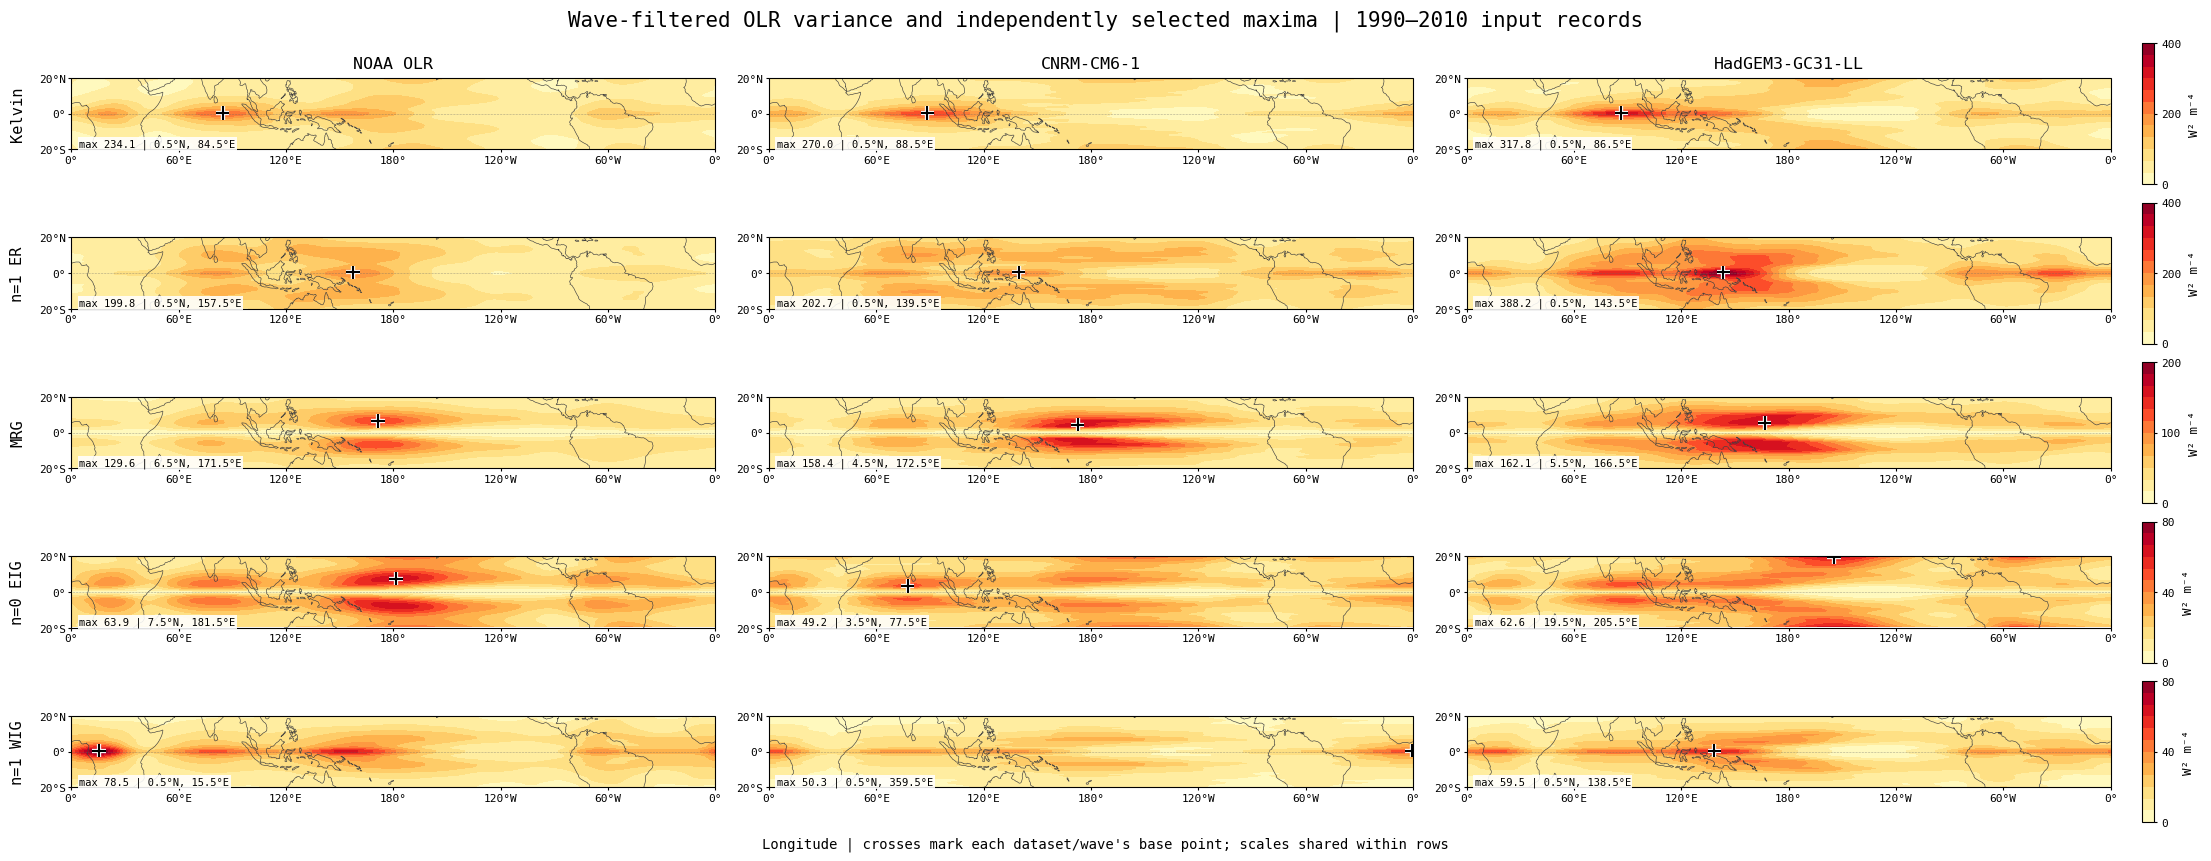

In [6]:
plot_wave_maps("filtered_variance")

## Average OLR structure: regression on the local filtered reference

Let $q_w(t)$ be wave-filtered OLR at its variance maximum and $Y'(t,\phi,\lambda)$
the unfiltered, untapered OLR anomaly. Define a positive convective index
$z_w(t)=-[q_w(t)-\overline q_w]/\sigma_w$. The fitted zero-lag response is

$$R_w(\phi,\lambda)=\frac{\operatorname{cov}(Y',z_w)}{\operatorname{var}(z_w)}
=-\frac{\operatorname{cov}(Y',q_w)}{\sigma_w}.$$

The default map is $R_w$: the anomaly associated with a **−1σ filtered-OLR
excursion**, with an intercept fitted. Blue/negative values indicate enhanced
convection; red/positive values indicate suppressed convection. The unfiltered
target has no imposed hemispheric symmetry. `REGRESSION_AMPLITUDE_SIGMA` above
can scale the fitted pattern to another excursion without repeating the analysis.

Each model is referenced to its **own** index standard deviation and base point.
Thus amplitude differences combine local wave variance and spatial coherence;
these are not regressions at a shared geographical reference or fixed W m⁻²
index amplitude.

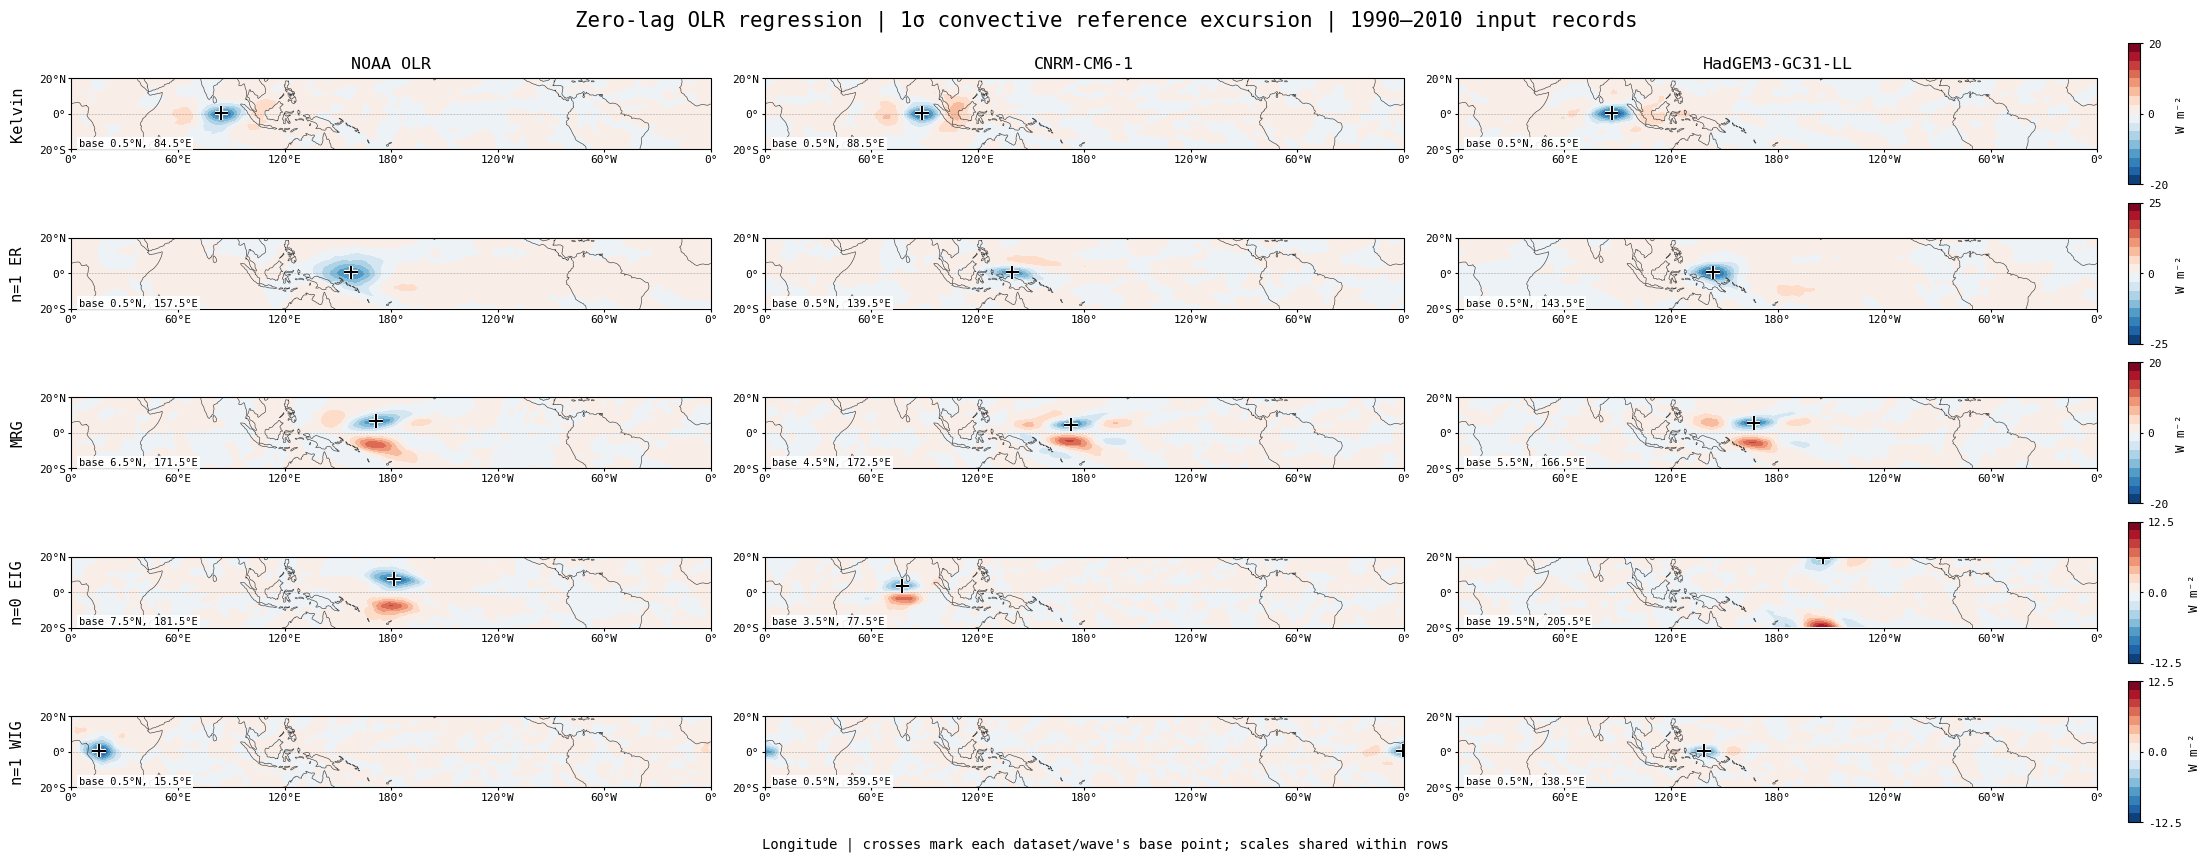

In [7]:
plot_wave_maps("regression")

## What these maps show

Kelvin variance peaks near the equator at 84.5–88.5°E in all three records.
The MRG maxima are farther east, at 166.5–172.5°E and 4.5–6.5°N. Under the
current broad ER filter, all three ER variance maxima lie at 0.5°N.

**HadGEM EIG has its maximum at 19.5°N, the northern edge of the domain.**
That base point is domain-limited; these maps do not locate an interior tropical
EIG maximum. The table flags this boundary case. Neither a broad filter label
nor the imposed predictor symmetry independently establishes physical wave
identity. In particular, the equatorial ER peaks and the edge EIG peak warrant
inspection before interpreting these bands as pure theoretical modes.

## Limits and reproduction

These are descriptive, all-season continuous-field diagnostics. The filters
admit broadband variability as well as coherent waves. A variance maximum or
regression pattern does not independently validate a wave identification or an
equivalent depth. Daily sampling also leaves propagation direction unresolved at
the exact 0.5 cycles/day Nyquist boundary admitted by the WIG box. No local-significance stippling is applied; serial dependence
and selection of the maximum would need attention for inference. The model–NOAA
peak ratios compare separately selected maxima, not colocated variance biases.

Reproduce the archive calculation on Levante with
`bash scripts/codex_olr_regression/submit.sh`, then copy the compact NetCDFs and
matching audit JSON files from `data/olr_wave_regression/1990-2010/` to the same
relative local directory. See
[`scripts/codex_olr_regression/README.md`](../scripts/codex_olr_regression/README.md)
for inputs, masks, preprocessing and output provenance. The notebook validates
product hashes, record identities, common code/grid, and the 15 selected maxima.
No standalone figures are written.